In [3]:
import gzip, idx2numpy, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras.models import Sequential
from keras.layers import Dense

In [4]:
CLASS = 17
THRESH = 1000
MAX_EPOCHS = 50
N_SAMPLE_PLOT= 10
PICKLE_FILE = 'dataset/data.pickle'
MAP_SYMBOLS = {'+': 10, '-': 11, 'x': 12, '/':13, '(':14, ')':15, ',':16}
VEC_SYMBOLS = np.vectorize(MAP_SYMBOLS.get)

# loading the dataset


In [6]:
data = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz', 't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']

for idx, filename in enumerate(data):
    with gzip.open('dataset/'+filename, 'rb') as f:
        temp = f.read()
        data[idx] = idx2numpy.convert_from_string(temp)
[X_train, y_train_label, X_test, y_test_label] = data

print("Train: ", X_train.shape, y_train_label.shape)
print("Test: ", X_test.shape, y_test_label.shape)

Train:  (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)


In [7]:
X_train = np.append(X_train, X_test, axis=0)
y_train_label = np.append(y_train_label, y_test_label, axis=0)
print('Train: ', X_train.shape, y_train_label.shape)

Train:  (70000, 28, 28) (70000,)


In [8]:
def thresholding(x, thresh):
    if x >= thresh:
        temp = 1
    else:
        temp=0
    return temp
thresholding_v = np.vectorize(thresholding)

In [9]:
X_train = thresholding_v(X_train, THRESH)

In [10]:
X_train = X_train.reshape(70000, -1)

In [11]:
# load symbol data
with open(PICKLE_FILE, 'rb') as f:
    symbol_train = pickle.load(f)
Xs_train = np.array(symbol_train['img'])
ys_train_label = VEC_SYMBOLS(np.array(symbol_train['label']))

print('Symbol: ', Xs_train.shape, ys_train_label.shape)

Symbol:  (4900, 28, 28) (4900,)


In [12]:
Xs_train = Xs_train.reshape(4900,-1)


In [13]:
temp = Xs_train
temp_label = ys_train_label
for i in range(9):
    temp = np.append(temp,Xs_train, axis=0)
    temp_label = np.append(temp_label, ys_train_label, axis=0)
print(temp.shape, temp_label.shape)
Xs_train = temp
ys_train_label = temp_label

(49000, 784) (49000,)


In [14]:
X_train = np.append(X_train, Xs_train, axis=0)
y_train_label = np.append(y_train_label, ys_train_label, axis=0)

In [16]:
print(X_train.shape, y_train_label.shape)

(119000, 784) (119000,)


In [17]:
y_train = np.eye(CLASS)[y_train_label]

# Train Model

In [18]:
# create model

model = Sequential()
model.add(Dense(20, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dense(20, activation='relu'))
model.add(Dense(CLASS, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer='Adam', metrics=['accuracy'])
model.summary()

2026-10-14 18:00:56.801117: I tensorflow/core/platform/cpu_feature_guard.cc:142] Your CPU supports instructions that this TensorFlow binary was not compiled to use: AVX2 FMA
2026-10-14 18:00:58.032273: I tensorflow/core/platform/profile_utils/cpu_utils.cc:94] CPU Frequency: 3593330000 Hz
2026-10-14 18:00:58.033433: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x55cc86206750 executing computations on platform Host. Devices:
2026-10-14 18:00:58.033473: I tensorflow/compiler/xla/service/service.cc:175]   StreamExecutor device (0): Host, Default Version


Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_1 (Dense)              (None, 20)                15700     
_________________________________________________________________
dense_2 (Dense)              (None, 20)                420       
_________________________________________________________________
dense_3 (Dense)              (None, 17)                357       
Total params: 16,477
Trainable params: 16,477
Non-trainable params: 0
_________________________________________________________________


In [19]:
history = model.fit(X_train, y_train, epochs=MAX_EPOCHS, verbose=0)

In [20]:
print("train score: ", round(model.evaluate(X_train, y_train)[1]*100,2), "%")

119000/119000 [==============================] - 1s 10us/step
train score:  47.8 %


In [21]:
model.save('model.h5')

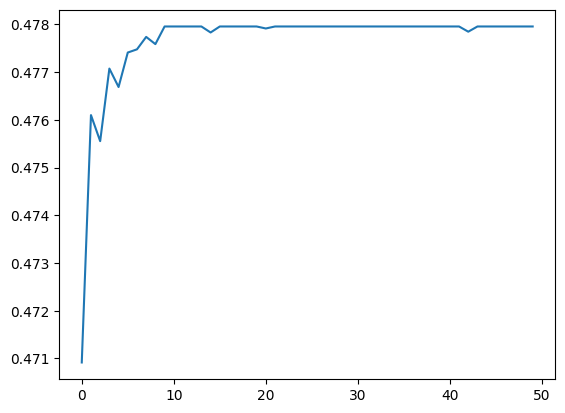

In [22]:
plt.plot(history.history['accuracy'])

Done...